# Student Learning Progress — Model Comparison

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style='whitegrid')
df = pd.read_csv('student_learning_progress_900_rows.csv')
print(df.shape)
print(df['progress_status'].value_counts())
df.isna().sum()

(900, 13)
progress_status
On Track           381
Improving          288
Needs Attention    231
Name: count, dtype: int64


student_id               0
session_date             0
subject                  0
session_number           0
study_duration_min      16
questions_attempted     10
questions_completed     10
completion_rate          0
previous_test_score    180
current_test_score       9
score_change           180
progress_status          0
next_test_score        180
dtype: int64

## 1. Data cleaning
- Normalize subject names, parse mixed date formats (`YYYY-MM-DD` and `DD/MM/YYYY`).
- Flag invalid study durations and inconsistent question counts.
- Recompute `completion_rate` where question counts are valid.

In [2]:
def clean(df):
    df = df.copy()
    df['subject'] = df['subject'].str.strip().str.title()

    # Mixed date formats
    d1 = pd.to_datetime(df['session_date'], format='%Y-%m-%d', errors='coerce')
    d2 = pd.to_datetime(df['session_date'], format='%d/%m/%Y', errors='coerce')
    df['session_date'] = d1.fillna(d2)

    # Invalid study durations: 0 or > 180 min
    df.loc[(df['study_duration_min'] <= 0) | (df['study_duration_min'] > 180),
           'study_duration_min'] = np.nan

    # Invalid question counts: no attempts, or more completed than attempted
    df.loc[df['questions_attempted'] <= 0,
           ['questions_attempted', 'questions_completed']] = np.nan
    df.loc[df['questions_completed'] > df['questions_attempted'],
           'questions_completed'] = np.nan

    # Recompute completion_rate where counts are now valid
    ok = df['questions_attempted'].notna() & df['questions_completed'].notna()
    df.loc[ok, 'completion_rate'] = (
        df.loc[ok, 'questions_completed'] / df.loc[ok, 'questions_attempted']
    ).clip(0, 1)

    # Fill count gaps so recomputed completion_rate stays consistent
    for col in ['study_duration_min', 'questions_attempted', 'questions_completed']:
        df[col] = df[col].fillna(df[col].median())
    return df

df = clean(df)
print('subjects:', sorted(df['subject'].unique()))
print('all dates parsed:', df['session_date'].notna().all())
df.isna().sum()

subjects: ['Biology', 'Chemistry', 'Computer Science', 'English', 'Mathematics', 'Physics']
all dates parsed: True


student_id               0
session_date             0
subject                  0
session_number           0
study_duration_min       0
questions_attempted      0
questions_completed      0
completion_rate          0
previous_test_score    180
current_test_score       9
score_change           180
progress_status          0
next_test_score        180
dtype: int64

## 2. Train / test split
Grouped by `student_id` so each student's sessions stay on one side.
Excluded features: `student_id` (identifier), `session_date` (no predictive meaning),
`next_test_score` (future), `score_change` (leak — it nearly determines the rule-generated label).

In [3]:
LEAK = ['student_id', 'session_date', 'next_test_score', 'score_change']
features = [c for c in df.columns if c not in LEAK + ['progress_status']]
X, y = df[features], df['progress_status']

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_i, test_i = next(gss.split(X, y, groups=df['student_id']))
X_tr, X_te, y_tr, y_te = X.iloc[train_i], X.iloc[test_i], y.iloc[train_i], y.iloc[test_i]
print('students: train', df['student_id'].iloc[train_i].nunique(), '/ test', df['student_id'].iloc[test_i].nunique())
print('rows: train', len(X_tr), '/ test', len(X_te))

students: train 45 / test 15
rows: train 675 / test 225


## 3. Pipelines

In [4]:
cat = ['subject']
num = [c for c in features if c not in cat]

pre_lr = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num)])

pre_rf = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ('num', SimpleImputer(strategy='median'), num)])

models = {
    'Logistic Regression': Pipeline([
        ('pre', pre_lr),
        ('model', LogisticRegression(max_iter=2000))]).fit(X_tr, y_tr),
    'Random Forest': Pipeline([
        ('pre', pre_rf),
        ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                         class_weight='balanced', random_state=42))]).fit(X_tr, y_tr),
}

In [5]:
results = {}
for name, pipe in models.items():
    pred = pipe.predict(X_te)
    results[name] = {
        'accuracy': accuracy_score(y_te, pred),
        'macro_precision': precision_score(y_te, pred, average='macro'),
        'macro_recall': recall_score(y_te, pred, average='macro'),
        'macro_f1': f1_score(y_te, pred, average='macro'),
    }
pd.DataFrame(results).T.round(3)

,accuracy,macro_precision,macro_recall,macro_f1
Logistic Regression,0.831,0.838,0.841,0.840
Random Forest,0.889,0.888,0.900,0.891


## 4. Graphs

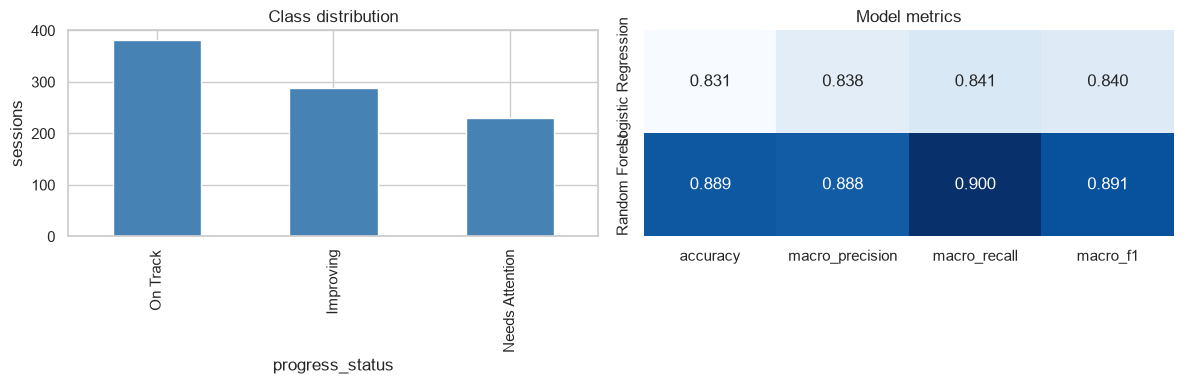

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['progress_status'].value_counts().plot.bar(ax=axes[0], color='steelblue')
axes[0].set_title('Class distribution')
axes[0].set_ylabel('sessions')
sns.heatmap(pd.DataFrame(results).T, annot=True, fmt='.3f', cmap='Blues',
            ax=axes[1], cbar=False)
axes[1].set_title('Model metrics')
plt.tight_layout()
plt.show()

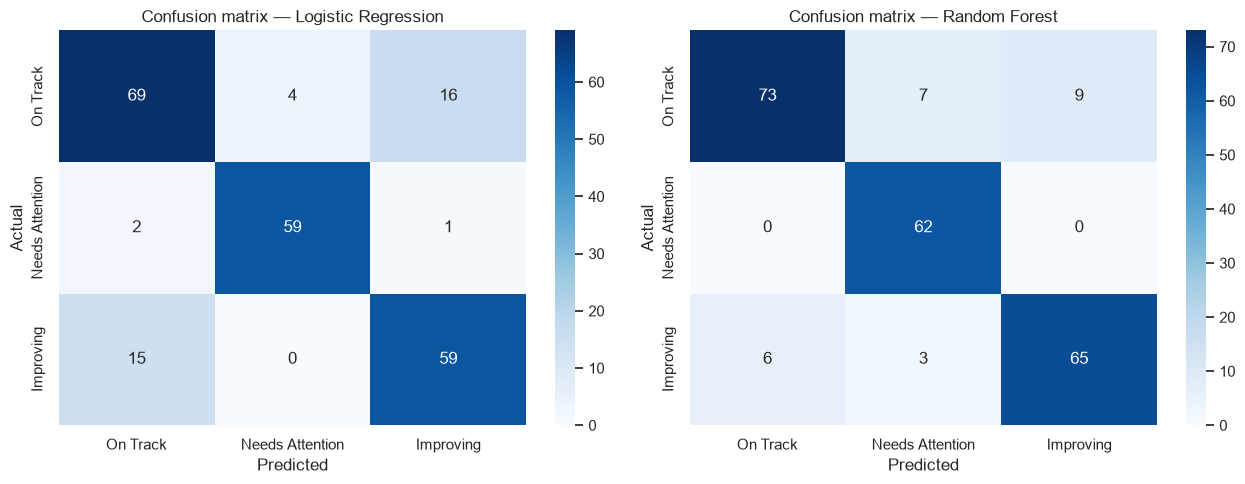

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = sorted(y.unique())[::-1]
for ax, name in zip(axes, results):
    cm = confusion_matrix(y_te, models[name].predict(X_te), labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels,
                yticklabels=labels, ax=ax)
    ax.set_title(f'Confusion matrix — {name}')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

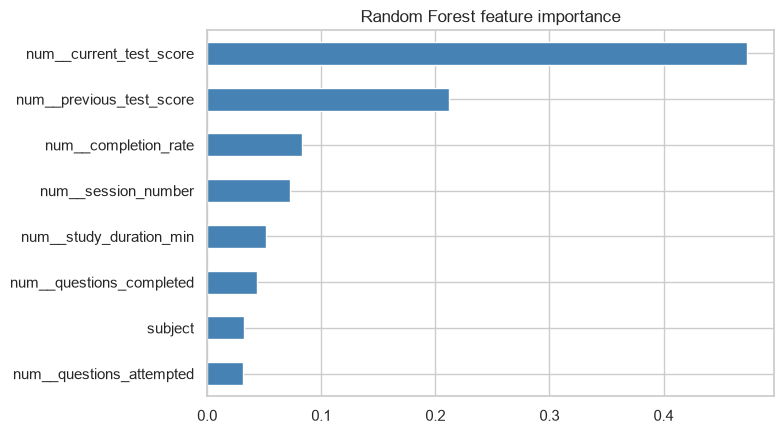

In [8]:
imp = pd.Series(models['Random Forest'].named_steps['model'].feature_importances_,
                index=models['Random Forest'].named_steps['pre'].get_feature_names_out())
imp['subject'] = imp[imp.index.str.startswith('cat__')].sum()
imp = imp.drop(imp.index[imp.index.str.startswith('cat__')]).sort_values()
imp.plot.barh(color='steelblue', figsize=(8, 4.5))
plt.title('Random Forest feature importance')
plt.tight_layout()
plt.show()

## 5. Select best model and save
Selected primarily by **macro F1**, accuracy as tiebreaker.

In [9]:
best = max(results, key=lambda m: (results[m]['macro_f1'], results[m]['accuracy']))
joblib.dump(models[best], 'model.pkl')
print(pd.DataFrame(results).T.round(3))
print(f'Selected: {best} -> model.pkl')
print('Limitation: labels are rule-generated from a synthetic dataset; accuracy reflects '
      'consistency with those rules, not real-world educational effectiveness.')

                     accuracy  macro_precision  macro_recall  macro_f1
Logistic Regression     0.831            0.838         0.841     0.840
Random Forest           0.889            0.888         0.900     0.891
Selected: Random Forest -> model.pkl
Limitation: labels are rule-generated from a synthetic dataset; accuracy reflects consistency with those rules, not real-world educational effectiveness.


In [10]:
# Example prediction on a new record
mdl = joblib.load('model.pkl')
new = pd.DataFrame([{
    'subject': 'Computer Science', 'session_number': 3, 'study_duration_min': 38,
    'questions_attempted': 18, 'questions_completed': 13, 'completion_rate': 0.722,
    'previous_test_score': 64, 'current_test_score': 73,
}])[X.columns]
print('Predicted:', mdl.predict(new)[0])
print(dict(zip(mdl.classes_, mdl.predict_proba(new)[0].round(3))))

Predicted: Improving
{'Improving': np.float64(0.755), 'Needs Attention': np.float64(0.025), 'On Track': np.float64(0.22)}
